In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 4.5 — Fixed and variable group dual actions

**Source:** SMSA 7.8, 2026-11-05, §§4.5.2–4.5.8, equations (4.52)–(4.60). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

At a fixed group element, (4.56) is inverse followed by transpose on the dual wire. We supply the two inverse matrices explicitly, using the integer shear from the representation of $\mathbb Z$ in §4.4.13. Native rigid rotation `.l` transposes the inverse coupon into a map on `V.l`, our translation of $V^*$. This is algebraic duality, with no complex conjugation.

In [1]:
from discopy import rigid, tensor
import numpy as np
V = rigid.Ty('V')
D = rigid.Box('D(g)', V, V)
Dinv = rigid.Box('D(g^-1)', V, V)
M = np.array([[1, 1], [0, 1]])
Minv = np.array([[1, -1], [0, 1]])
F = tensor.Functor({V: 2}, {D: M.T, Dinv: Minv.T}, dom=rigid.Category(), dtype=int)
Ddual = Dinv.l

(4.56) computed dual matrix:
 [[ 1  0]
 [-1  1]]
Expected inverse transpose:
 [[ 1  0]
 [-1  1]]
Equal: True
Supplied inverse, product M @ Minv:
 [[1 0]
 [0 1]]


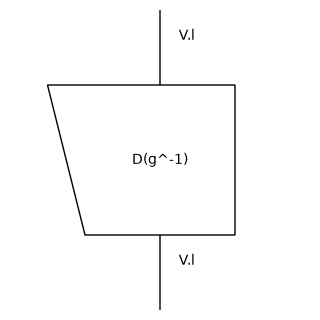

In [2]:
Ddual.draw(figsize=(3, 3))
print('(4.56) computed dual matrix:\n', F(Ddual).array.T)
print('Expected inverse transpose:\n', Minv.T)
print('Equal:', np.array_equal(F(Ddual).array.T, Minv.T))
print('Supplied inverse, product M @ Minv:\n', M @ Minv)

(4.51) transformed pairing:
 [[1 0]
 [0 1]]
Original pairing:
 [[1 0]
 [0 1]]
Equal: True


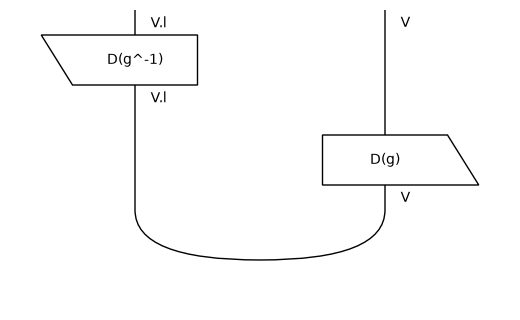

In [3]:
ev = rigid.Cup(V.l, V)
pairing_after_action = (Ddual @ D) >> ev
pairing_after_action.draw(figsize=(5, 3))
print('(4.51) transformed pairing:\n', F(pairing_after_action).array)
print('Original pairing:\n', F(ev).array)
print('Equal:', F(pairing_after_action) == F(ev))

**Variable group input, (4.60).** For a second, chosen example let $G=\mathbb Z_3$ and $D(1)=M=\begin{pmatrix}0&-1\\1&-1\end{pmatrix}$, with $D(0)=I$ and $D(2)=M^2$. This is illustrative data, not a matrix copied from SMSA. The group wire is $A=\mathbb F[\mathbb Z_3]$. The antipode sends $b_i$ to $b_{-i}$.

The diagram uses that antipode, a flip, a cap, the original action and a cup. Its input is $A\otimes V^*$ and its output is $V^*$. This section uses native `compact` objects, where the shared dual prints as `V.r`. The earlier rigid example uses `V.l`. Both realize the same algebraic dual in the chosen vector-space model. Native drawings omit SMSA's small bend arrows.

The matrices are not orthogonal, so inverse transpose is visibly different from the original action. The check compares all three dual matrices, then both representation-law expressions for all nine pairs of group basis elements. These are finite instances of (4.61), not its general graphical proof.

(4.60) boundary: A @ V.r -> V.r
Expected boundary: A @ V.r -> V.r
Original matrices I, M, M squared:
 [[[ 1  0]
  [ 0  1]]

 [[ 0 -1]
  [ 1 -1]]

 [[-1  1]
  [-1  0]]]
Computed dual matrices:
 [[[ 1  0]
  [ 0  1]]

 [[-1 -1]
  [ 1  0]]

 [[ 0  1]
  [-1 -1]]]
Expected inverse transposes:
 [[[ 1  0]
  [ 0  1]]

 [[-1 -1]
  [ 1  0]]

 [[ 0  1]
  [-1 -1]]]
All three equal: True


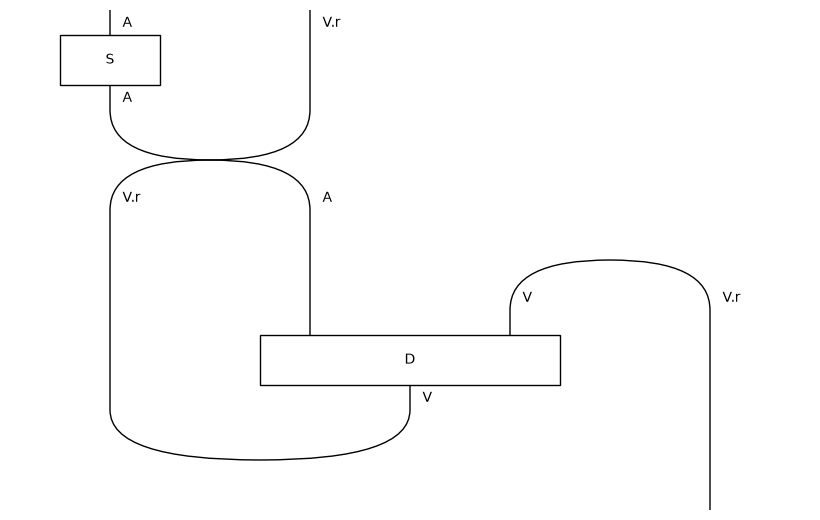

In [4]:
from discopy import compact, tensor
import numpy as np
A, V = compact.Ty('A'), compact.Ty('V')
Vr = V.r
S = compact.Box('S', A, A)
rho = compact.Box('D', A @ V, V)
mu = compact.Box('mu', A @ A, A)
M = np.array([[0,-1],[1,-1]])
matrices = np.array([np.eye(2,dtype=int), M, M @ M])
rho_data = matrices.transpose(0,2,1)
S_data = np.eye(3,dtype=int)[[0,2,1]]
mu_data = np.array([[[int(k == (i+j)%3) for k in range(3)] for j in range(3)] for i in range(3)])
F = tensor.Functor({A:3,V:2}, {S:S_data,rho:rho_data,mu:mu_data}, dom=compact.Category(), dtype=int)
bend = compact.Id(Vr @ A) @ compact.Cap(V,Vr)
act = compact.Id(Vr) @ rho @ compact.Id(Vr)
close = compact.Cup(Vr,V) @ compact.Id(Vr)
dual_action = (S @ compact.Id(Vr)) >> compact.Swap(A,Vr) >> bend >> act >> close
expected = matrices[[0,2,1]].transpose(0,2,1)
actual = F(dual_action).array.transpose(0,2,1)
print('(4.60) boundary:', dual_action.dom, '->', dual_action.cod)
print('Expected boundary:', A @ Vr, '->', Vr)
print('Original matrices I, M, M squared:\n', matrices)
print('Computed dual matrices:\n', actual)
print('Expected inverse transposes:\n', expected)
print('All three equal:', np.array_equal(actual, expected))
dual_action.draw(figsize=(8,5))


In [5]:
left = (mu @ compact.Id(Vr)) >> dual_action
right = (compact.Id(A) @ dual_action) >> dual_action
print('(4.61) computed product-then-action array:\n', F(left).array)
print('Expected successive-actions array:\n', F(right).array)
print('All nine pairs equal:', F(left) == F(right))
without_S = compact.Swap(A,Vr) >> bend >> act >> close
print('Control without antipode, generator 1:\n', F(without_S).array[1].T)
print('Required dual matrix for generator 1:\n', expected[1])
print('Control matches (expected False):', np.array_equal(F(without_S).array, F(dual_action).array))


(4.61) computed product-then-action array:
 [[[[ 1  0]
   [ 0  1]]

  [[-1  1]
   [-1  0]]

  [[ 0 -1]
   [ 1 -1]]]


 [[[-1  1]
   [-1  0]]

  [[ 0 -1]
   [ 1 -1]]

  [[ 1  0]
   [ 0  1]]]


 [[[ 0 -1]
   [ 1 -1]]

  [[ 1  0]
   [ 0  1]]

  [[-1  1]
   [-1  0]]]]
Expected successive-actions array:
 [[[[ 1  0]
   [ 0  1]]

  [[-1  1]
   [-1  0]]

  [[ 0 -1]
   [ 1 -1]]]


 [[[-1  1]
   [-1  0]]

  [[ 0 -1]
   [ 1 -1]]

  [[ 1  0]
   [ 0  1]]]


 [[[ 0 -1]
   [ 1 -1]]

  [[ 1  0]
   [ 0  1]]

  [[-1  1]
   [-1  0]]]]
All nine pairs equal: True
Control without antipode, generator 1:
 [[ 0  1]
 [-1 -1]]
Required dual matrix for generator 1:
 [[-1 -1]
 [ 1  0]]
Control matches (expected False): False


**Remaining scope.** The general graphical proof of (4.61) remains in SMSA. The notebook checks the chosen three-element group representation. No general Hopf-algebra rewrite system is supplied.